In [2]:
from google.colab import files
uploaded = files.upload()

Saving house-prices-advanced-regression-techniques (1).zip to house-prices-advanced-regression-techniques (1) (1).zip


In [3]:
import pandas as pd
import zipfile
import os

# Find the uploaded Kaggle ZIP file
zip_name = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

# Extract the dataset files
data_dir = "/content/house_prices_data"
os.makedirs(data_dir, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    for name in z.namelist():
        filename = os.path.basename(name)
        if filename in [
            "train.csv",
            "test.csv",
            "data_description.txt",
            "sample_submission.csv"
        ]:
            with z.open(name) as src:
                with open(os.path.join(data_dir, filename), "wb") as dst:
                    dst.write(src.read())

# Load the original Kaggle training dataset
df = pd.read_csv(os.path.join(data_dir, "train.csv"))

print("Dataset shape:", df.shape)
print("SalePrice exists:", "SalePrice" in df.columns)
print(df["SalePrice"].describe())

Dataset shape: (1460, 81)
SalePrice exists: True
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [10]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('/content/house_prices_data/train.csv')

print("PART 3 SETUP")
print("=" * 50)
print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

PART 3 SETUP
Dataset loaded successfully
Dataset shape: (1460, 81)

First five rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
print("SalePrice exists:", "SalePrice" in df.columns)
print(df["SalePrice"].describe())

SalePrice exists: True
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [12]:
# Check missing values and column data types

print("Dataset shape:", df.shape)

print("\nColumns with the most missing values:")
print(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(15)
)

print("\nData types:")
print(df.dtypes.value_counts())

Dataset shape: (1460, 81)

Columns with the most missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64

Data types:
object     43
int64      35
float64     3
Name: count, dtype: int64


In [13]:
# Check missing values as percentages
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percent": (missing / len(df) * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percent", ascending=False)
)

print("Columns with missing values:", len(missing_summary))
display(missing_summary.head(20))

Columns with missing values: 19


,Missing_Count,Missing_Percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [14]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (1168, 79)
Testing features: (292, 79)
Training targets: (1168,)
Testing targets: (292,)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns from training data
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing: fill missing values with training medians
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 36
Categorical features: 43
Preprocessing pipeline created successfully.


In [16]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Combine preprocessing and Ridge regression
ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

# Fit using training data only
ridge_model.fit(X_train, y_train)

# Predict on held-out test data
y_pred = ridge_model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RIDGE REGRESSION RESULTS")
print("=" * 35)
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:    {r2:.4f}")

RIDGE REGRESSION RESULTS
MAE:  $19,040.56
RMSE: $30,646.31
R²:    0.8776


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Linear Regression with the same preprocessing
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train on the same training data
linear_model.fit(X_train, y_train)

# Predict the same test data
linear_pred = linear_model.predict(X_test)

# Compare results
print("LINEAR REGRESSION RESULTS")
print("=" * 35)
print(f"MAE:  ${mean_absolute_error(y_test, linear_pred):,.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, linear_pred)):,.2f}")
print(f"R²:    {r2_score(y_test, linear_pred):.4f}")

print("\nRIDGE REGRESSION RESULTS")
print(f"MAE:  ${mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"R²:    {r2_score(y_test, y_pred):.4f}")

LINEAR REGRESSION RESULTS
MAE:  $18,287.70
RMSE: $29,473.87
R²:    0.8867

RIDGE REGRESSION RESULTS
MAE:  $19,040.56
RMSE: $30,646.31
R²:    0.8776


In [18]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print("5-FOLD CROSS-VALIDATION")
print("=" * 35)
print(f"Mean R²:   {cv_results['test_r2'].mean():.4f}")
print(f"Std R²:    {cv_results['test_r2'].std():.4f}")
print(f"Mean MAE:  ${-cv_results['test_mae'].mean():,.2f}")
print(f"Mean RMSE: ${-cv_results['test_rmse'].mean():,.2f}")

5-FOLD CROSS-VALIDATION
Mean R²:   0.7700
Std R²:    0.0835
Mean MAE:  $19,621.55
Mean RMSE: $36,396.35


In [19]:
print("R² score for each fold:")
for i, score in enumerate(cv_results["test_r2"], start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMAE for each fold:")
for i, score in enumerate(cv_results["test_mae"], start=1):
    print(f"Fold {i}: ${-score:,.2f}")

print("\nRMSE for each fold:")
for i, score in enumerate(cv_results["test_rmse"], start=1):
    print(f"Fold {i}: ${-score:,.2f}")

R² score for each fold:
Fold 1: 0.8593
Fold 2: 0.7516
Fold 3: 0.6527
Fold 4: 0.8696
Fold 5: 0.7168

MAE for each fold:
Fold 1: $19,937.00
Fold 2: $19,334.72
Fold 3: $20,805.56
Fold 4: $18,331.51
Fold 5: $19,698.95

RMSE for each fold:
Fold 1: $30,161.34
Fold 2: $38,130.27
Fold 3: $48,363.44
Fold 4: $26,675.11
Fold 5: $38,651.59


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import numpy as np

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=1
)

print("RANDOM FOREST: 5-FOLD CROSS-VALIDATION")
print("=" * 42)
print(f"Mean R²:   {rf_cv['test_r2'].mean():.4f}")
print(f"Std R²:    {rf_cv['test_r2'].std():.4f}")
print(f"Mean MAE:  ${-rf_cv['test_mae'].mean():,.2f}")
print(f"Mean RMSE: ${-rf_cv['test_rmse'].mean():,.2f}")

print("\nLINEAR REGRESSION: 5-FOLD CROSS-VALIDATION")
print(f"Mean R²:   {cv_results['test_r2'].mean():.4f}")
print(f"Mean MAE:  ${-cv_results['test_mae'].mean():,.2f}")
print(f"Mean RMSE: ${-cv_results['test_rmse'].mean():,.2f}")

RANDOM FOREST: 5-FOLD CROSS-VALIDATION
Mean R²:   0.8400
Std R²:    0.0440
Mean MAE:  $18,307.84
Mean RMSE: $30,624.09

LINEAR REGRESSION: 5-FOLD CROSS-VALIDATION
Mean R²:   0.7700
Mean MAE:  $19,621.55
Mean RMSE: $36,396.35


In [21]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Fit the selected model on the complete training split
rf_model.fit(X_train, y_train)

# Predict the held-out test split
rf_pred = rf_model.predict(X_test)

# Final test metrics
print("RANDOM FOREST: HELD-OUT TEST RESULTS")
print("=" * 42)
print(f"MAE:  ${mean_absolute_error(y_test, rf_pred):,.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, rf_pred)):,.2f}")
print(f"R²:    {r2_score(y_test, rf_pred):.4f}")

RANDOM FOREST: HELD-OUT TEST RESULTS
MAE:  $17,524.44
RMSE: $28,848.70
R²:    0.8915


TOP 15 FEATURE IMPORTANCES


,Feature,Importance
3,numeric__OverallQual,0.562495
15,numeric__GrLivArea,0.124173
11,numeric__TotalBsmtSF,0.033849
13,numeric__2ndFlrSF,0.030748
8,numeric__BsmtFinSF1,0.027816
12,numeric__1stFlrSF,0.026679
2,numeric__LotArea,0.017910
26,numeric__GarageArea,0.015819
25,numeric__GarageCars,0.014373
5,numeric__YearBuilt,0.012135


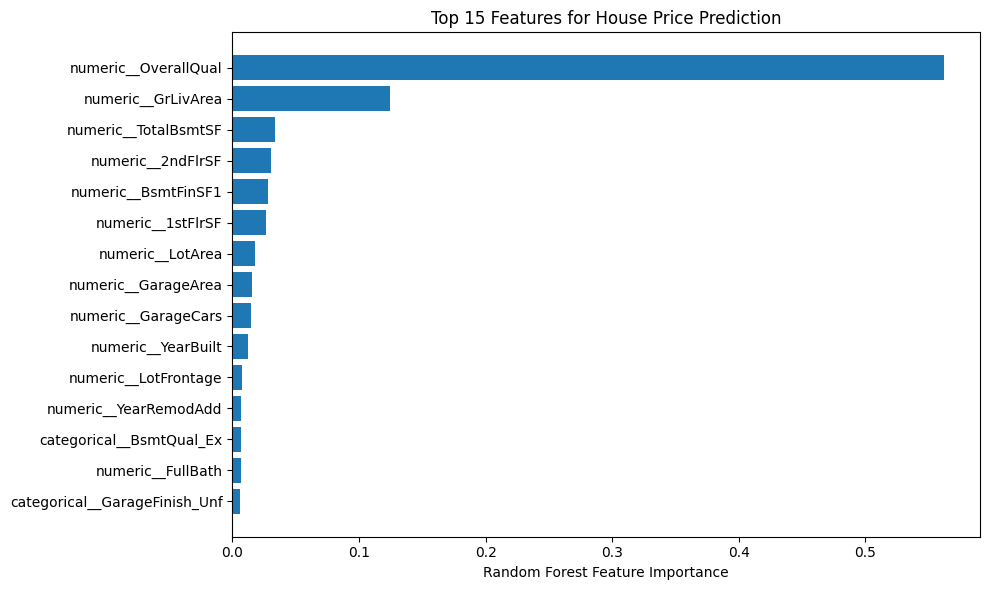

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the fitted preprocessing and Random Forest model
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_forest = rf_model.named_steps["model"]

# Get names of transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Build feature-importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_forest.feature_importances_
})

# Show the 15 most important transformed features
importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print("TOP 15 FEATURE IMPORTANCES")
display(importance_df.head(15))

# Plot the top 15
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Random Forest Feature Importance")
plt.title("Top 15 Features for House Price Prediction")
plt.tight_layout()
plt.show()

In [23]:
results_summary = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "CV_R2_Mean": cv_results["test_r2"].mean(),
        "CV_R2_Std": cv_results["test_r2"].std(),
        "CV_MAE": -cv_results["test_mae"].mean(),
        "CV_RMSE": -cv_results["test_rmse"].mean(),
        "Test_R2": r2_score(y_test, linear_pred),
        "Test_MAE": mean_absolute_error(y_test, linear_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, linear_pred))
    },
    {
        "Model": "Random Forest",
        "CV_R2_Mean": rf_cv["test_r2"].mean(),
        "CV_R2_Std": rf_cv["test_r2"].std(),
        "CV_MAE": -rf_cv["test_mae"].mean(),
        "CV_RMSE": -rf_cv["test_rmse"].mean(),
        "Test_R2": r2_score(y_test, rf_pred),
        "Test_MAE": mean_absolute_error(y_test, rf_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, rf_pred))
    }
])

display(results_summary.round(4))

results_summary.to_csv(
    "/content/house_price_model_results.csv",
    index=False
)

print("Results saved successfully.")

,Model,CV_R2_Mean,CV_R2_Std,CV_MAE,CV_RMSE,Test_R2,Test_MAE,Test_RMSE
0,Linear Regression,0.77,0.0835,19621.5492,36396.3522,0.8867,18287.6986,29473.8731
1,Random Forest,0.84,0.0440,18307.8418,30624.0886,0.8915,17524.4380,28848.7044


Results saved successfully.


In [ ]:
# Create feature matrix and target labels

X = df.drop(columns=['SalePrice'])

y_reg = df['SalePrice']

y_clf = (y_reg > y_reg.median()).astype(int)


# Identify categorical columns

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()


# Ordinal columns with natural order

ordinal_columns = [
    'ExterQual',
    'ExterCond',
    'HeatingQC',
    'KitchenQual'
]

ordinal_mapping = {
    'Po': 0,
    'Fa': 1,
    'TA': 2,
    'Gd': 3,
    'Ex': 4
}


# Encode ordinal columns

X_encoded = X.copy()

for column in ordinal_columns:
    X_encoded[column] = X_encoded[column].map(ordinal_mapping)


# One-hot encode nominal categorical columns

nominal_columns = [
    column for column in categorical_columns
    if column not in ordinal_columns
]

X_encoded = pd.get_dummies(
    X_encoded,
    columns=nominal_columns,
    drop_first=True
)


# Fill any remaining missing values

X_encoded = X_encoded.fillna(X_encoded.median())


print("PART 3 SETUP")
print("=" * 50)

print("\nOriginal X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)

print("\nClassification label counts:")
print(y_clf.value_counts().sort_index())

print("\nTotal missing values in X_encoded:",
      X_encoded.isnull().sum().sum())

PART 3 SETUP

Original X shape: (1460, 80)
Encoded X shape: (1460, 235)

Classification label counts:
SalePrice
0    732
1    728
Name: count, dtype: int64

Total missing values in X_encoded: 0


In [ ]:
# Split features and classification labels

X_train, X_test, y_clf_train, y_clf_test = train_test_split(
    X_encoded,
    y_clf,
    test_size=0.2,
    random_state=42
)


# Fit scaler only on training features

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("PART 3 SETUP COMPLETE")
print("=" * 50)

print("\nX_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\ny_clf_train shape:", y_clf_train.shape)
print("y_clf_test shape:", y_clf_test.shape)

print("\nSetup complete. Ready for Task 1.")

PART 3 SETUP COMPLETE

X_train_scaled shape: (1168, 235)
X_test_scaled shape: (292, 235)

y_clf_train shape: (1168,)
y_clf_test shape: (292,)

Setup complete. Ready for Task 1.


TASK 1: DECISION TREE BASELINE

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train unconstrained Decision Tree
decision_tree_baseline = DecisionTreeClassifier(
    random_state=42
)

decision_tree_baseline.fit(
    X_train_scaled,
    y_clf_train
)

# Generate predictions
y_train_pred_tree = decision_tree_baseline.predict(X_train_scaled)
y_test_pred_tree = decision_tree_baseline.predict(X_test_scaled)

# Calculate accuracies
train_accuracy_tree = accuracy_score(
    y_clf_train,
    y_train_pred_tree
)

test_accuracy_tree = accuracy_score(
    y_clf_test,
    y_test_pred_tree
)

print("TASK 1: DECISION TREE BASELINE")
print("=" * 50)

print("\nTraining Accuracy:", train_accuracy_tree)
print("Test Accuracy:", test_accuracy_tree)
print("Train-Test Accuracy Gap:",
      train_accuracy_tree - test_accuracy_tree)

TASK 1: DECISION TREE BASELINE

Training Accuracy: 1.0
Test Accuracy: 0.8972602739726028
Train-Test Accuracy Gap: 0.10273972602739723


TASK 2: CONTROLLED DECISION TREE

In [ ]:
decision_tree_controlled = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    random_state=42
)

decision_tree_controlled.fit(X_train_scaled, y_clf_train)

train_accuracy_controlled = decision_tree_controlled.score(
    X_train_scaled, y_clf_train
)

test_accuracy_controlled = decision_tree_controlled.score(
    X_test_scaled, y_clf_test
)

print("TASK 2: CONTROLLED DECISION TREE")
print("=" * 50)

print("\nTraining Accuracy:", train_accuracy_controlled)
print("Test Accuracy:", test_accuracy_controlled)

TASK 2: CONTROLLED DECISION TREE

Training Accuracy: 0.9272260273972602
Test Accuracy: 0.8767123287671232


TASK 3: GINI vs ENTROPY COMPARISON

In [ ]:
# Train Decision Tree using Gini criterion

gini_tree = DecisionTreeClassifier(
    max_depth=5,
    criterion='gini',
    random_state=42
)

gini_tree.fit(X_train_scaled, y_clf_train)

gini_test_accuracy = gini_tree.score(
    X_test_scaled,
    y_clf_test
)


# Train Decision Tree using Entropy criterion

entropy_tree = DecisionTreeClassifier(
    max_depth=5,
    criterion='entropy',
    random_state=42
)

entropy_tree.fit(X_train_scaled, y_clf_train)

entropy_test_accuracy = entropy_tree.score(
    X_test_scaled,
    y_clf_test
)


print("TASK 3: GINI VS ENTROPY COMPARISON")
print("=" * 50)

print("\nGini Test Accuracy:", gini_test_accuracy)
print("Entropy Test Accuracy:", entropy_test_accuracy)

TASK 3: GINI VS ENTROPY COMPARISON

Gini Test Accuracy: 0.8938356164383562
Entropy Test Accuracy: 0.9006849315068494


TASK 4: RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Train Random Forest model

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

model.fit(X_train_scaled, y_clf_train)


# Training and test accuracy

rf_train_accuracy = model.score(
    X_train_scaled,
    y_clf_train
)

rf_test_accuracy = model.score(
    X_test_scaled,
    y_clf_test
)


# Test ROC-AUC

rf_test_probabilities = model.predict_proba(
    X_test_scaled
)[:, 1]

rf_test_auc = roc_auc_score(
    y_clf_test,
    rf_test_probabilities
)


# Get feature importance scores

feature_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": model.feature_importances_
})

top_5_features = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(5)


print("TASK 4: RANDOM FOREST")
print("=" * 50)

print("\nTraining Accuracy:", rf_train_accuracy)
print("Test Accuracy:", rf_test_accuracy)
print("ROC-AUC:", rf_test_auc)

print("\nTop 5 Features by Importance:")
print(top_5_features.to_string(index=False))

TASK 4: RANDOM FOREST

Training Accuracy: 0.9957191780821918
Test Accuracy: 0.9452054794520548
ROC-AUC: 0.9844483428950737

Top 5 Features by Importance:
    Feature  Importance
  GrLivArea    0.083904
  YearBuilt    0.060458
OverallQual    0.059282
   FullBath    0.051729
TotalBsmtSF    0.037707


4 a: GRADIENT BOOSTING

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Train Gradient Boosting model

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_model.fit(
    X_train_scaled,
    y_clf_train
)


# Training and test accuracy

gb_train_accuracy = gradient_boosting_model.score(
    X_train_scaled,
    y_clf_train
)

gb_test_accuracy = gradient_boosting_model.score(
    X_test_scaled,
    y_clf_test
)


# Test ROC-AUC

gb_test_probabilities = gradient_boosting_model.predict_proba(
    X_test_scaled
)[:, 1]

gb_test_auc = roc_auc_score(
    y_clf_test,
    gb_test_probabilities
)


print("TASK 4a: GRADIENT BOOSTING")
print("=" * 50)

print("\nTraining Accuracy:", gb_train_accuracy)
print("Test Accuracy:", gb_test_accuracy)
print("ROC-AUC:", gb_test_auc)

TASK 4a: GRADIENT BOOSTING

Training Accuracy: 0.9888698630136986
Test Accuracy: 0.9452054794520548
ROC-AUC: 0.9857285097909061


4 b: FEATURE ABLATION STUDY

In [ ]:
# Identify the 5 features with the lowest importance scores

lowest_5_features = feature_importance.sort_values(
    by="Importance",
    ascending=True
).head(5)

features_to_remove = lowest_5_features["Feature"].tolist()


# Find their column indices

feature_indices_to_remove = [
    X_encoded.columns.get_loc(feature)
    for feature in features_to_remove
]


# Remove the 5 lowest-importance features

X_train_reduced = np.delete(
    X_train_scaled,
    feature_indices_to_remove,
    axis=1
)

X_test_reduced = np.delete(
    X_test_scaled,
    feature_indices_to_remove,
    axis=1
)


# Train second Random Forest with identical hyperparameters

reduced_random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

reduced_random_forest.fit(
    X_train_reduced,
    y_clf_train
)


# Calculate reduced-model test ROC-AUC

reduced_test_probabilities = reduced_random_forest.predict_proba(
    X_test_reduced
)[:, 1]

reduced_test_auc = roc_auc_score(
    y_clf_test,
    reduced_test_probabilities
)


print("TASK 4b: FEATURE ABLATION STUDY")
print("=" * 50)

print("\n5 Features with Lowest Importance:")
print(lowest_5_features.to_string(index=False))

print("\nFull Model Test ROC-AUC:", rf_test_auc)
print("Reduced Model Test ROC-AUC:", reduced_test_auc)

TASK 4b: FEATURE ABLATION STUDY

5 Features with Lowest Importance:
           Feature  Importance
     LotConfig_FR3         0.0
       Street_Pave         0.0
   Condition2_RRNn         0.0
Exterior1st_CBlock         0.0
   Condition2_RRAe         0.0

Full Model Test ROC-AUC: 0.9844483428950737
Reduced Model Test ROC-AUC: 0.9852069603148261


TASK 5: CROSS- VALIDATED COMPARISON

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

# Define 5-fold stratified cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Define the four required models

logistic_regression = LogisticRegression(
    max_iter=1000
)

controlled_decision_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    random_state=42
)

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)


# Models to compare

models = {
    "Logistic Regression": logistic_regression,
    "Controlled Decision Tree": controlled_decision_tree,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}


# Perform 5-fold cross-validation

cv_results = []

for model_name, current_model in models.items():

    auc_scores = cross_val_score(
        current_model,
        X_train_scaled,
        y_clf_train,
        cv=cv,
        scoring='roc_auc'
    )

    cv_results.append({
        "Model": model_name,
        "Mean AUC": auc_scores.mean(),
        "Std AUC": auc_scores.std()
    })


# Create comparison table

cv_comparison_table = pd.DataFrame(cv_results)


print("TASK 5: CROSS-VALIDATED COMPARISON")
print("=" * 60)

print("\n5-Fold Cross-Validation ROC-AUC Results:")
print(cv_comparison_table.to_string(index=False))

TASK 5: CROSS-VALIDATED COMPARISON

5-Fold Cross-Validation ROC-AUC Results:
                   Model  Mean AUC  Std AUC
     Logistic Regression  0.956086 0.008220
Controlled Decision Tree  0.924300 0.014311
           Random Forest  0.977065 0.004617
       Gradient Boosting  0.973368 0.008429


TASK 6: HYPERPARAMETER TUNING WITH GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# Define parameter grid

param_grid = {
    'randomforestclassifier__n_estimators': [50, 100, 200],
    'randomforestclassifier__max_depth': [5, 10, None],
    'randomforestclassifier__min_samples_leaf': [1, 5]
}


# Build pipeline

pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    RandomForestClassifier(random_state=42)
)


# Define GridSearchCV

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring='roc_auc',
    n_jobs=-1
)


# Fit on unscaled training data

grid_search.fit(
    X_train,
    y_clf_train
)


# Get best results

best_params = grid_search.best_params_
best_score = grid_search.best_score_
best_pipeline = grid_search.best_estimator_


print("TASK 6: HYPERPARAMETER TUNING WITH GRIDSEARCHCV")
print("=" * 70)

print("\nBest Parameters:")
print(best_params)

print("\nBest Cross-Validation ROC-AUC:")
print(best_score)

print("\nTotal Model Configurations Evaluated:", 18)
print("Total Fits Including 5 Folds:", 18 * 5)

TASK 6: HYPERPARAMETER TUNING WITH GRIDSEARCHCV

Best Parameters:
{'randomforestclassifier__max_depth': 10, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.9782964711437587

Total Model Configurations Evaluated: 18
Total Fits Including 5 Folds: 90


TASK 7: MANUAL LEARNING CURVE

In [ ]:
fractions = [0.2, 0.4, 0.6, 0.8, 1.0]

learning_curve_results = []

for fraction in fractions:

    subset_size = int(fraction * len(X_train))

    X_train_subset = X_train.iloc[:subset_size]
    y_train_subset = y_clf_train.iloc[:subset_size]

    best_pipeline.fit(
        X_train_subset,
        y_train_subset
    )

    train_probabilities = best_pipeline.predict_proba(
        X_train_subset
    )[:, 1]

    train_auc = roc_auc_score(
        y_train_subset,
        train_probabilities
    )

    test_probabilities = best_pipeline.predict_proba(
        X_test
    )[:, 1]

    test_auc = roc_auc_score(
        y_clf_test,
        test_probabilities
    )

    learning_curve_results.append({
        "Training fraction": fraction,
        "Training AUC": train_auc,
        "Test AUC": test_auc
    })

learning_curve_table = pd.DataFrame(learning_curve_results)

print("TASK 7: MANUAL LEARNING CURVE")
print("=" * 60)

print("\nManual Learning Curve Results:")
print(learning_curve_table.to_string(index=False))

TASK 7: MANUAL LEARNING CURVE

Manual Learning Curve Results:
 Training fraction  Training AUC  Test AUC
               0.2      1.000000  0.979778
               0.4      1.000000  0.982457
               0.6      0.999992  0.984354
               0.8      0.999986  0.984164
               1.0      0.999941  0.984448


TASK 8: SERIALIZE THE BEST MODEL

In [ ]:
import joblib

# Save the best pipeline

joblib.dump(
    best_pipeline,
    'best_model.pkl'
)


# Load the saved model

loaded_model = joblib.load(
    'best_model.pkl'
)


# Predict on two test rows

sample_test_rows = X_test.iloc[:2]

sample_predictions = loaded_model.predict(
    sample_test_rows
)


print("TASK 8: SERIALIZE THE BEST MODEL")
print("=" * 60)

print("\nModel saved successfully as best_model.pkl")
print("Model loaded successfully")

print("\nSample predictions on two test rows:")
print(sample_predictions)

TASK 8: SERIALIZE THE BEST MODEL

Model saved successfully as best_model.pkl
Model loaded successfully

Sample predictions on two test rows:
[0 1]


TASK 9: SUMMARY COMPARISON TABLE

In [ ]:
# Fit models before test-set prediction
logistic_regression.fit(X_train_scaled, y_clf_train)
controlled_decision_tree.fit(X_train_scaled, y_clf_train)

# Calculate test-set AUC

logistic_test_auc = roc_auc_score(
    y_clf_test,
    logistic_regression.predict_proba(X_test_scaled)[:, 1]
)

controlled_tree_test_auc = roc_auc_score(
    y_clf_test,
    controlled_decision_tree.predict_proba(X_test_scaled)[:, 1]
)

# Create summary comparison table

summary_table = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Controlled Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "5-Fold CV Mean AUC": cv_comparison_table["Mean AUC"].values,
    "5-Fold CV Std AUC": cv_comparison_table["Std AUC"].values,
    "Test-Set AUC": [
        logistic_test_auc,
        controlled_tree_test_auc,
        rf_test_auc,
        gb_test_auc
    ]
})

print("TASK 9: SUMMARY COMPARISON TABLE")
print("=" * 80)

print("\nFinal Model Comparison:")
print(summary_table.to_string(index=False))

TASK 9: SUMMARY COMPARISON TABLE

Final Model Comparison:
                   Model  5-Fold CV Mean AUC  5-Fold CV Std AUC  Test-Set AUC
     Logistic Regression            0.956086           0.008220      0.966336
Controlled Decision Tree            0.924300           0.014311      0.938410
           Random Forest            0.977065           0.004617      0.984448
       Gradient Boosting            0.973368           0.008429      0.985729


# Part 3: Advanced Modeling for House Price Prediction

## 1. Project Objective
The objective of this project is to predict house sale prices using machine learning regression models and evaluate their performance on unseen data.

## 2. Dataset
The project uses the Kaggle House Prices dataset, containing 1,460 training records and 79 input features after excluding the `Id` and `SalePrice` columns from the features.

## 3. Data Preprocessing
- Separated the target variable (`SalePrice`) from the input features.
- Split the data into training and testing sets using an 80:20 ratio.
- Imputed missing numerical values using the median.
- Imputed missing categorical values using the most frequent value.
- Standardized numerical features and one-hot encoded categorical features.
- Used scikit-learn pipelines to keep preprocessing within model training and cross-validation.

## 4. Models Evaluated
- Linear Regression
- Ridge Regression
- Random Forest Regressor

## 5. Results
Random Forest achieved the strongest held-out test performance among the evaluated models.

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| Cross-validation mean R² | 0.7700 | 0.8400 |
| Test R² | 0.8867 | 0.8915 |
| Test MAE | $18,287.70 | $17,524.44 |
| Test RMSE | $29,473.87 | $28,848.70 |

## 6. Feature Importance
The Random Forest model identified `OverallQual` (overall material and finish quality) as its most influential feature, followed by `GrLivArea` (above-ground living area) and `TotalBsmtSF` (total basement area).

Feature importance describes the model's use of features; it does not establish that a feature causes a higher sale price.

## 7. Conclusion
Random Forest outperformed Linear Regression on the held-out test set, achieving an R² of 0.8915. Its cross-validation mean R² was 0.8400, indicating good predictive performance across the training folds.

The results are specific to this dataset and evaluation split. Model performance may vary on new houses and different datasets.